In [1]:
import os
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.metrics import accuracy_score

# if the dataset isn't available download and save it as file
if not os.path.exists("mnist.npz"):
    from sklearn.datasets import fetch_openml
    import numpy as np

    mnist = fetch_openml("mnist_784", version=1, as_frame=False) # return pd DataFrame by default

    X = mnist.data
    y = mnist.target

    np.savez_compressed("mnist.npz", X=X, y=y, allow_pickle=True)
    print("Dataset downloaded and saved.")
else:
    print("Dataset already exist.")

Dataset already exist.


In [2]:
with np.load("mnist.npz", allow_pickle=True) as data:
    print(data.files)
    print(data["X"].shape)
    print(data["y"].shape)

    x = data["X"]
    y = data["y"]


['X', 'y']
(70000, 784)
(70000,)


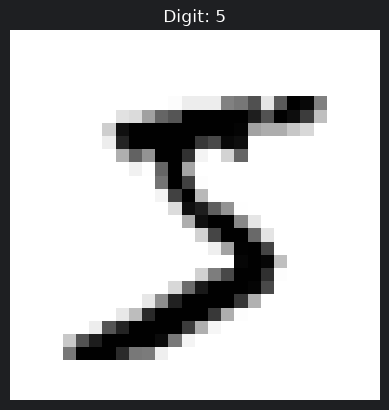

In [3]:
# Plot the first image
import matplotlib.pyplot as plt

data = np.load("mnist.npz", allow_pickle=True)
plt.imshow(x[0].reshape(28, 28), cmap="binary")
plt.title(f"Digit: {y[0]}")
plt.axis("off")
plt.show()

### Separate training and test set. We split it like this (0-60k, 60k-70k) only because the dataset is already shuffled for us. If not, that test set would not be good representation of reality.

In [4]:
X_train, X_test = x[:60000], x[60000:]
y_train, y_test = y[:60000], y[60000:]


print(y[:5])
print(x[:5])

['5' '0' '4' '1' '9']
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


## Training a Binary Classifier
Train the model to be a 5 detector. It distingushes between 5 and non-5

In [5]:
y_train = y_train.astype(np.uint8)
y_test = y_test.astype(np.uint8)

y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)

# Pick a classifier Algorithm. Start with Stochastic Gradient Descent classifier

from sklearn.linear_model import SGDClassifier
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

sgd_clf.predict(X_test)

array([False, False, False, ..., False,  True, False], shape=(10000,))

## Performance Measure
When training a model what we actually care about is how the model perform on data it never seen. This ability is called generalization. Finding the true general signal from the noisy observation. Evaluating classifier's performance is trickier than evaluating regressor.

In [6]:
# Use k-fold cross validation

from sklearn.model_selection import cross_val_score
cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy")  # 3 fold

array([0.95035, 0.96035, 0.9604 ])

### Nice, above 95% accuracy!

But don't be excited. The mnist data set is skewed (only about 9% of the data is 5) hence a model that learn nothing and predict a number is non-5 every time will have 91% accuracy.

Or to make it clear if there are 99% healthy people, the model then predict everyone as healthy it achieves 99% accuracy.

**Is this model useful?** No. Hence accuracy gives us a false sense being good.

---

### Let's use Dummy Classifier,

Dummy will just give prediction for most frequent data. In our case non-5, so everytime it predicts non-5.

In [7]:
from sklearn.dummy import DummyClassifier
dummy_clf = DummyClassifier()
dummy_clf.fit(X_train, y_train_5)
print(any(dummy_clf.predict(X_train)))

# Check Dummy classifier accuracy

cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring="accuracy")


False


array([0.90965, 0.90965, 0.90965])

Above 90% accurate, that's because about 90% of the data is non-5. This demonstrates why accuracy is not preferred performance measure for classifier specially when we are dealign with a skewed data. A better way is looking at Confusion Matrix.

Cross_val_score Vs Cross_val_predict!

In [8]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)
cm = confusion_matrix(y_train_5, y_train_pred)
print(cm)


[[53892   687]
 [ 1891  3530]]


Great, Refer about confusion matrix. The row is the actual class and the columns are the predicted values. A perfect model would have non zero value in diagonal only. From the confusion matric we can a lot of information, accuracy, precision, recall...

In [9]:
# Example for perfect model

y_train_5_perfection = y_train_5
cm = confusion_matrix(y_train_5, y_train_5_perfection)
print(cm)

[[54579     0]
 [    0  5421]]


# 🎯 Precision and Recall

## 1. Precision

**Precision:** out of all predicted as positive how many of them are actually positive?

$$
P = \frac{TP}{TP + FP}
$$

It is a valuable metrics when the model can't afford having false positive. We optimize for precision when having more accurate positive is more important than missing some positive. It measure wether what you are saying positive is actually positive.
>
> **Question:** Does the model need to accurately classify a sample as a true positive to reduce the number of false positives? If yes, then optimize for better precision.

---

## 2. Recall

**Recall:** Out of all real positive hoe many of them were predicted as positive?

$$
R = \frac{TP}{TP + FN}
$$

We optimize for rcall when identifying all positive is crucial. Ex. detecting cyber attack or bank fraud, here missing TP is more costly than further examinations. Recall is focused on not missing out positive observations.

> **Question:** Does the model need to detect all positive samples at the risk of a false negative? If yes, then optimize for better recall.

---

### Precision-Recall Curve

But what is the relation between precision and recall in a model? We can plot them in graph and examine precision-recall curve.



## 3. F1 Score

F1 SCORE combine both precision and recall so the model is optimized for best of both simultaneously.

$$
F1\ Score = \frac{2 * precision * recall}{precision + recall}
$$

This valued represent harmonic mean between precision and recall and is standard metric in inbalanced classification problem. Whereas the regular mean treats all values equally, the harmonic mean gives much more weight to low values. As a result, the classifier will only get a high F1 score if both recall and precision are high.

A perfect F1 score is 1. Unfortunately we can't increase both precision and recall together, this is called precision/recall tradeoff.

In [10]:
from sklearn.metrics import precision_score, recall_score
print(precision_score(y_train_5, y_train_pred))
recall_score(y_train_5, y_train_pred)

0.8370879772350012


0.6511713705958311

Now our 5-detector model doesn't look shiny like it did when we analyze it using accuracy. When it claim a number is 5 it's correct 83% of the time but it detect only 65% of 5 from our dataset.

### F1_score

In [11]:
from sklearn.metrics import f1_score
f1_score(y_train_5, y_train_pred)

0.7325171197343847

But now we want to play with precision/recall tradeoff. We increase one based on our goal.

The classifier algorithm produce decision score first (for all individual image) then prepare a threshold point which will be used to compare the score with and predict the image. When the score exceed the threshold it predicts positive, if below threshold it predicts negative.

The score tells you where the example falls relative to the classifier's decision boundary.
The threshold determines how strict the classifier is about predicting the positive class.

Scikit Learn doesn't let us set threshold directly but give us access to the decision score. So instead of calling the classifiers predict() method we call decision_function() method which return score for each instance, then we use any treshold we want.

In [16]:
y_scores = sgd_clf.decision_function([X_train[0]])
print(y_scores)

threshold = 0
y_first_pred = (y_scores > threshold).astype(np.uint8)
print(y_first_pred)

threshold = 3000   # We put the bar higher
y_first_pred = (y_scores > threshold).astype(np.uint8)
print(y_first_pred)

[2164.22030239]
[1]
[0]


This confirms that raising the threshold decreases recall. The image actually represents a 5, and the classifier detects it when the threshold is 0, but it misses it when the threshold is increased to 3,000.

How do you decide which threshold to use? First, use the cross_val_predict() function to get the scores of all  instances in the training set, but this time specify that you want to return decision scores instead of predictions:

In [18]:
y_score = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, method="decision_function")
print(y_score)

[  1200.93051237 -26883.79202424 -33072.03475406 ...  13272.12718981
  -7258.47203373 -16877.50840447]


Now we need to visualise the score.

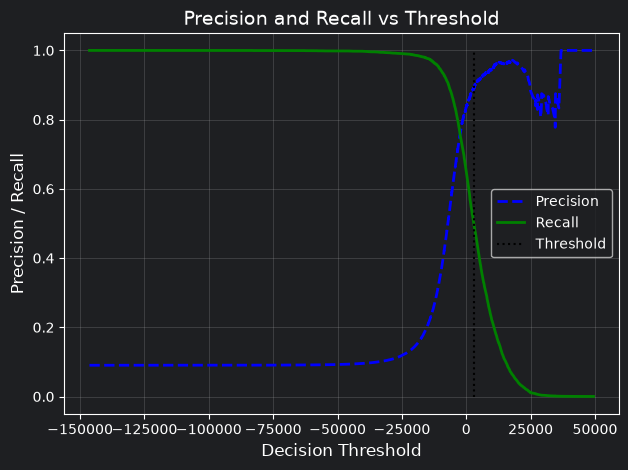

In [20]:
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_score)

# Use mathplot to plot (SPEC AI CODE)
# This plot precision and recall versus decision threshold

plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)

plt.vlines(threshold, 0, 1.0, "k", "dotted", label="Threshold")

plt.xlabel("Decision Threshold", fontsize=12)
plt.ylabel("Precision / Recall", fontsize=12)
plt.title("Precision and Recall vs Threshold", fontsize=14)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()